# IND320 Compulsory Assignment 3

Elias Vinsrygg

This notebook documents Compulsory Assignment 3 in the course IND320.

## 1. Project links

- Public GitHub repository: [https://github.com/EliasVinsrygg/IND320-EliasVinsrygg](https://github.com/EliasVinsrygg/IND320-EliasVinsrygg)
- Published Streamlit app: [https://ind320-eliasvinsrygg.streamlit.app/](https://ind320-eliasvinsrygg.streamlit.app/)
- Screencast, explaining the submission: LINK

## 2. Work Log
CA3 required less "setup-work" and more theoretical understanding than the previous Compulsories. In addition to stuff I remember from the classes, a combination of D2D book reading, Panopto-watching and AI discussion was necessary in order to understand what's going actually going on. Challnging but interesting. 

Notebook:
- After doenloading shapefiles, the random sampling was done. Then came the task of downloading data for the 1000 points in NO3. As I quickly got in trouble with the open-meteo download timelimits, I had to include a timed pause between each request in order to get all data without error messages. I decided that I would try to work around this problem when developing the app later. 
- Next was Presipitation SPC and DCT and temperature LOF. I set the sigma to 5 solely because looking at the precipitation data, I felt that the outlier selection became to strict with lower boundaries. But since we're not doing much with the identified outliers, I feel like it doesn't matter much right now. If we later will use this data to make a prediction model, it might be more relevant to assess which outliers should be excluded from the dataset, depending on f.ex how much data we're training the model on. 
- Reservoir filling spectrogram was a bit hard to comprehend, but some graph stearing helped.

Streamlit:
- After the experience of having to implement timed pauses in the downloading in the notebook work, I decided that I want to use lower quality on the weather data used for the app. Open-meteo has a calculator with computes API calls different types of requests costs. Using 2 variables for one full year, I figured that 100 coordinates will reuire 521,4 API calls, wich is under the 600 calls/minute limit. Therefore, I went with 100 points as standard for the app, and downloaded data for all regions in 2024 and 2025 and put it into mongoDB. If the user wants to download data that is not in mongoDB, he or she will be asked if they want to proceed with downloading. New data will be added to mongoDB, and the're are time limits making shure that a user cannot download too much. 
- New pages are grouped together with reservoir data, because it's about the different regions within Norway. the cross border flow page is another topic, and is therefore in it's own grouping. The data-table page is now updated so the user can look at data from all the datasets used. 

## 3. AI Usage

I use ChatGPT and Codex actively as development tools when working on the assignments. My goal is to learn to be an efficient developer by using agentic coding to improve productivity without compromising my understanding or the quality of the final product.

My typical workflow is to discuss problems and possible solutions with the AI agent before arriving at a solution that I review and approve. Codex is then used to generate or modify code based on specific instructions. Code that I've written myself is also looked over by Codex, so I can get input on how to improve it.

In CA3, I used AI to explain and implement weather downloads, and to adjust material from the D2D book about DCT/SPC, LOF, STL and spectrograms to my case. AI also helped with testing, debugging and Streamlit integration, including MongoDB storage and download controls, based on my instructions. 

 An important principle for me is that I should understand the code and the solutions we develop. I frequently ask the agent to explain problems and suggest some alternatives. 

## 4. Importing stuff

In [ ]:
from pathlib import Path
import geopandas as gpd
import numpy as np
import pandas as pd
import hashlib
import json
import time
import requests
import tomllib
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation, trim_mean
from pymongo import MongoClient, UpdateOne
from pymongo.errors import PyMongoError
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL

## 5. Regions and Random Sampling

The shapefiles are downloaded from [atlas.nve.no](https://atlas.nve.no/vertigisstudio/web/?app=e0080b63a0c445a5a47e6d8c3b53ad8c) and is used to find 1000 random points for each region.

In [4]:
# Locating the source folder when running from the notebook folder or repository root.
shapefile_folder = next(
    folder for folder in (
        Path("../shapefiles"),
        Path("Compulsory Assignments/shapefiles"),
        Path("shapefiles"),
    ) if folder.is_dir()
)
points_per_region = 1000
random_seed = 42

# Reading geometry and attributes together, using UTF-8 to preserve Norwegian letters.
electricity_areas = gpd.read_file(
    shapefile_folder / "Budområder/Budområder.shp", encoding="utf-8"
)
nve_regions = gpd.read_file(
    shapefile_folder / "NVE_Region/NVE_Region.shp", encoding="utf-8"
)

# Matching the assignment's regional grouping before drawing any points.
electricity_areas["region"] = electricity_areas["budomr"].str.replace(" ", "", regex=False)
electricity_areas["area_type"] = "EL"
region_mapping = {"RS": "VASS1", "RØ": "VASS1", "RV": "VASS2", "RM": "VASS3", "RN": "VASS3"}
assert nve_regions["REGION"].isin(region_mapping).all(), "Unexpected NVE region code."
nve_regions["region"] = nve_regions["REGION"].map(region_mapping)
nve_regions["area_type"] = "VASS"

# Using an equal-area projection to distribute sampled points uniformly over ground area.
electricity_areas = electricity_areas.to_crs("EPSG:3035")
nve_regions = nve_regions.to_crs("EPSG:3035").dissolve(by="region", as_index=False)
regions = gpd.GeoDataFrame(
    pd.concat([
        electricity_areas[["area_type", "region", "geometry"]],
        nve_regions[["area_type", "region", "geometry"]],
    ], ignore_index=True),
    crs="EPSG:3035",
).sort_values("region").reset_index(drop=True)
assert regions.geometry.is_valid.all() and not regions.geometry.is_empty.any()

# Drawing 1000 points inside each region, using a fixed seed to reproduce the sample.
sampled_points = regions.set_geometry(
    regions.geometry.sample_points(
        size=points_per_region, rng=np.random.default_rng(random_seed)
    ).rename("geometry")
)
sampled_points = sampled_points.explode(ignore_index=True)
sampled_points["point_id"] = sampled_points.groupby("region").cumcount() + 1

# Verifying the count and regional membership before converting to longitude/latitude.
for region in regions.itertuples():
    selected_points = sampled_points.loc[sampled_points["region"] == region.region]
    assert len(selected_points) == points_per_region
    assert selected_points.geometry.within(region.geometry).all()
assert not sampled_points.duplicated(subset=["region", "geometry"]).any()

sampled_points = sampled_points.to_crs("EPSG:4326")
sampled_points["longitude"] = sampled_points.geometry.x
sampled_points["latitude"] = sampled_points.geometry.y

# Keeping separate coordinate lists for the later region-based weather downloader.
region_locations = {
    region: list(zip(group["longitude"], group["latitude"]))
    for region, group in sampled_points.groupby("region")
}
sample_summary = sampled_points.groupby(["area_type", "region"]).size().rename("locations")
sample_summary

area_type  region
EL         NO1       1000
           NO2       1000
           NO3       1000
           NO4       1000
           NO5       1000
VASS       VASS1     1000
           VASS2     1000
           VASS3     1000
Name: locations, dtype: int64

## 6. Historical Weather Data

First, we make a function that takes a region identifier and time interval as input, looks up the corresponing list of coordinates and downloads chosen variables. Since we're limited to a certain amount of API calls per minute and hour (and this comsumes time), we cache the data so it can be accessed even if the cell is stoped for any reason.

In [ ]:
def download_weather(
    region_id: str, start_date: str, end_date: str, *,
    batch_size: int = 100, pause_seconds: float = 420.0,
) -> pd.DataFrame:
    """Download hourly ERA5 temperature and precipitation for the selected region.

    Dates include both days in UTC. Batches are saved locally and reused on rerun.
    The default pause spaces new request starts by seven minutes. This reduces
    quota pressure for NO3/2024, but cannot account for other API usage.
    Only a complete dataset for all 1000 selected points is returned.
    """
    # Checking the selected sample and settings before contacting the API.
    if region_id not in region_locations:
        raise ValueError(f"Unknown region: {region_id}")
    locations = np.asarray(region_locations[region_id], dtype=float)
    if locations.shape != (1000, 2) or not np.isfinite(locations).all():
        raise ValueError("The region must contain 1000 finite longitude/latitude pairs.")
    if (np.abs(locations) > [180, 90]).any():
        raise ValueError("Coordinates are outside longitude/latitude bounds.")
    if not isinstance(batch_size, int) or not 1 <= batch_size <= 100:
        raise ValueError("batch_size must be an integer from 1 to 100.")
    if not np.isfinite(pause_seconds) or pause_seconds < 0:
        raise ValueError("pause_seconds must be finite and non-negative.")
    start = pd.to_datetime(start_date, format="%Y-%m-%d", utc=True)
    end = pd.to_datetime(end_date, format="%Y-%m-%d", utc=True)
    if pd.isna(start) or pd.isna(end) or start > end:
        raise ValueError("The date interval must be valid and ordered.")
    expected_times = pd.date_range(start, end + pd.Timedelta(days=1), freq="h", inclusive="left")
    variables = ["temperature_2m", "precipitation"]
    units = {"temperature_2m": "°C", "precipitation": "mm"}
    url = "https://archive-api.open-meteo.com/v1/archive"
    cache_folder = shapefile_folder.resolve().parent / "data" / "weather" / region_id / "batches"
    cache_folder.mkdir(parents=True, exist_ok=True)
    frames, last_request_time = [], None
    batch_count = (len(locations) + batch_size - 1) // batch_size

    with requests.Session() as session:
        for offset in range(0, len(locations), batch_size):
            # Combining matching coordinate pairs into one multi-location request.
            batch = locations[offset:offset + batch_size]
            longitudes, latitudes = batch.T
            params = {
                "latitude": ",".join(map(str, latitudes)),
                "longitude": ",".join(map(str, longitudes)),
                "start_date": start.strftime("%Y-%m-%d"),
                "end_date": end.strftime("%Y-%m-%d"),
                "hourly": ",".join(variables), "models": "era5", "timezone": "GMT",
                "temperature_unit": "celsius", "precipitation_unit": "mm",
            }
            # Matching cached batches by coordinates, dates and all API settings.
            request_key = hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()
            cache_path = cache_folder / f"{request_key}.json"
            cached = cache_path.is_file()
            if cached:
                payload = json.loads(cache_path.read_text(encoding="utf-8"))
            else:
                # Spacing new request starts; saved batches require no waiting.
                if last_request_time is not None:
                    time.sleep(max(0, pause_seconds - (time.monotonic() - last_request_time)))
                last_request_time = time.monotonic()
                response = session.get(url, params=params, timeout=180)
                if response.status_code == 429:
                    raise RuntimeError(
                        f"Open-Meteo quota reached: {response.text}. "
                        "Completed batches are saved. Rerun after the quota resets."
                    )
                response.raise_for_status()
                payload = response.json()

            # Checking one response per requested point before saving the batch.
            responses = payload if isinstance(payload, list) else [payload]
            if len(responses) != len(batch):
                raise ValueError("The API returned an unexpected number of locations.")
            for index, point_data in enumerate(responses):
                frame = pd.DataFrame(point_data["hourly"])[["time", *variables]]
                frame["time"] = pd.to_datetime(frame["time"], utc=True)
                if not pd.DatetimeIndex(frame["time"]).equals(expected_times):
                    raise ValueError("Unexpected hourly coverage in a weather response.")
                if any(point_data["hourly_units"].get(v) != units[v] for v in variables):
                    raise ValueError("Unexpected weather units.")
                frame[variables] = frame[variables].apply(pd.to_numeric, errors="raise")
                if not np.isfinite(frame[variables].to_numpy(dtype=float)).all():
                    raise ValueError("Missing or non-finite weather values.")
                # Keeping point IDs and requested coordinates for regional averaging.
                frame["region"], frame["point_id"] = region_id, offset + index + 1
                frame["longitude"], frame["latitude"] = batch[index]
                frame["grid_longitude"] = point_data["longitude"]
                frame["grid_latitude"] = point_data["latitude"]
                frames.append(frame)

            # Saving validated batches atomically so interrupted writes can be rerun.
            if not cached:
                temporary_path = cache_path.with_suffix(".tmp")
                temporary_path.write_text(json.dumps(payload, allow_nan=False), encoding="utf-8")
                temporary_path.replace(cache_path)
            print(f"Batch {offset // batch_size + 1}/{batch_count}: "
                  f"{offset + len(batch)}/1000 points complete ({'cached' if cached else 'downloaded'})")

    # Returning the complete point-level table with source, time zone and units.
    weather_data = pd.concat(frames, ignore_index=True)
    weather_data.attrs = {"model": "era5", "timezone": "UTC", "units": units, "source": url}
    return weather_data


Applying the function to download data for NO3 for 2024: As this exeeded the hourly limit from the provider, it took a approximately 80 minutes to complete. 

In [6]:
# Downloading or resuming hourly ERA5 data for the 1000 NO3 points for UTC year 2024.
no3_weather_2024 = download_weather(
    region_id="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31",
)

# Previewing the downloaded table without displaying millions of rows.
no3_weather_2024.head()

Batch 1/10: 100/1000 points complete (cached)
Batch 2/10: 200/1000 points complete (cached)
Batch 3/10: 300/1000 points complete (cached)
Batch 4/10: 400/1000 points complete (cached)
Batch 5/10: 500/1000 points complete (cached)
Batch 6/10: 600/1000 points complete (cached)
Batch 7/10: 700/1000 points complete (cached)
Batch 8/10: 800/1000 points complete (cached)
Batch 9/10: 900/1000 points complete (cached)
Batch 10/10: 1000/1000 points complete (cached)


,time,temperature_2m,precipitation,region,point_id,longitude,latitude,grid_longitude,grid_latitude
0,2024-01-01 00:00:00+00:00,-2.6,0.0,NO3,1,8.578309,63.134683,8.5,63.25
1,2024-01-01 01:00:00+00:00,-2.9,0.0,NO3,1,8.578309,63.134683,8.5,63.25
2,2024-01-01 02:00:00+00:00,-3.0,0.0,NO3,1,8.578309,63.134683,8.5,63.25
3,2024-01-01 03:00:00+00:00,-3.1,0.0,NO3,1,8.578309,63.134683,8.5,63.25
4,2024-01-01 04:00:00+00:00,-3.1,0.0,NO3,1,8.578309,63.134683,8.5,63.25


## 7. Precipitation: DCT and SPC

This cell performs Discrete Cosine Transform on the precipitation data, which provides the base for establishin Statistical Process Contloll lines that defines the accepted data from flagged outliers. In periods with more presipitations, higher values are accepted as normal values. 

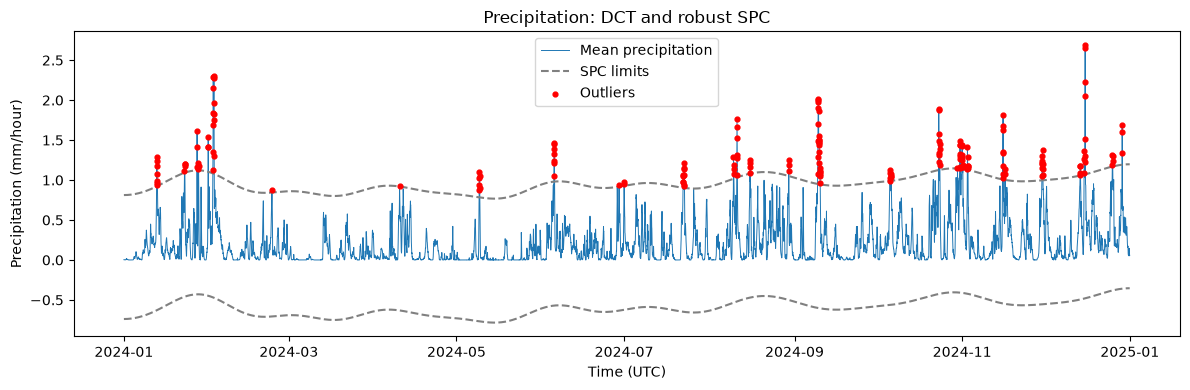

hours              8784.000000
outlier_hours       181.000000
outlier_percent       2.060565
robust_sigma_mm       0.155106
dtype: float64

,precipitation,lower,upper
time,,,
2024-01-12 22:00:00+00:00,1.0817,-0.630422,0.920638
2024-01-12 23:00:00+00:00,1.2373,-0.629721,0.921340
2024-01-13 00:00:00+00:00,1.2943,-0.629018,0.922042
2024-01-13 01:00:00+00:00,1.1740,-0.628313,0.922747
2024-01-13 02:00:00+00:00,0.9887,-0.627608,0.923452


In [ ]:
def precipitation_spc(weather, cutoff=1 / 30, n_std=3):
    """Plot hourly regional precipitation with robust DCT-based SPC limits.

    Input contains one complete year of regular UTC hourly point data.
    cutoff is in cycles/day; 1/30 removes periods longer than 30 days.
    Returns the figure, outlier table and whole-year summary.
    """
    # Averaging the sampled points for each hour, retaining precipitation in mm.
    rain = weather.groupby("time")["precipitation"].mean().sort_index()
    if not 0 < cutoff < 12 or n_std <= 0:
        raise ValueError("cutoff must be between 0 and 12 cycles/day; n_std must be positive.")

    # Removing low frequencies using the course's type-1 DCT and matching inverse.
    coefficients = dct(rain.to_numpy(), type=1, norm="forward")
    frequencies = np.arange(len(rain)) / (2 * (len(rain) - 1) / 24)
    coefficients[frequencies < cutoff] = 0
    satv = idct(coefficients, type=1, norm="forward")

    # Estimating robust location and spread from the entire filtered year.
    center = trim_mean(satv, 0.05)
    sigma = 1.4826 * median_abs_deviation(satv)
    if sigma == 0:
        raise ValueError("MAD is zero; robust SPC limits cannot be estimated.")
    baseline = rain - satv
    lower = baseline + center - n_std * sigma
    upper = baseline + center + n_std * sigma
    outside = (rain < lower) | (rain > upper)
    outliers = pd.DataFrame({"precipitation": rain, "lower": lower, "upper": upper}).loc[outside]
    summary = pd.Series({"hours": len(rain), "outlier_hours": int(outside.sum()),
                         "outlier_percent": 100 * outside.mean(), "robust_sigma_mm": sigma})

    # Showing the original precipitation and shifted limits, without plotting SATV.
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(rain.index, rain, label="Mean precipitation", linewidth=0.7)
    ax.plot(rain.index, lower, "--", color="gray", label="SPC limits")
    ax.plot(rain.index, upper, "--", color="gray")
    ax.scatter(outliers.index, outliers["precipitation"], color="red", s=12, label="Outliers", zorder=3)
    ax.set(xlabel="Time (UTC)", ylabel="Precipitation (mm/hour)", title="Precipitation: DCT and robust SPC")
    ax.legend()
    fig.tight_layout()
    return fig, outliers, summary


# Testing the function on the downloaded year, reading only the required columns.
weather = no3_weather_2024[["time", "precipitation"]]
spc_figure, precipitation_outliers, spc_summary = precipitation_spc(weather, n_std=5)
plt.show()
display(spc_summary, precipitation_outliers.head())


## 8. Temperature: LOF

In this cell, each point gets a calculated LOF score, and this is used to flagg the most anormal points. 

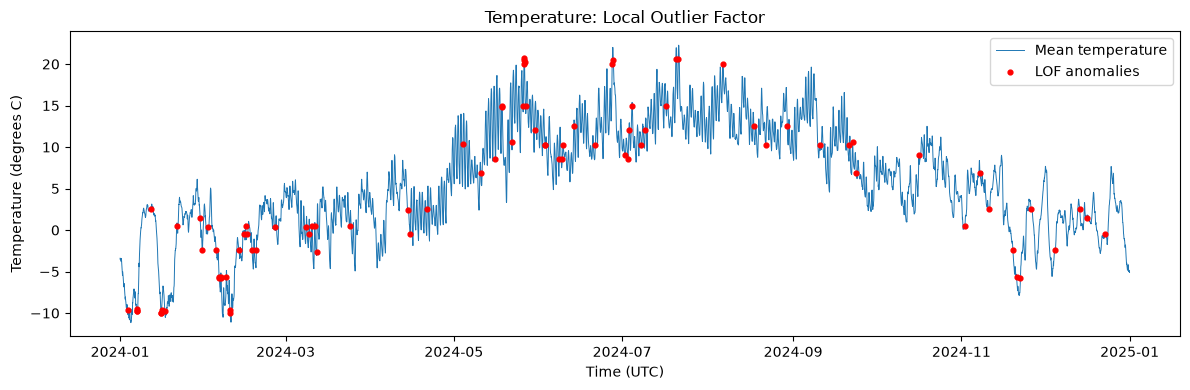

hours              8784.000000
outlier_hours        88.000000
outlier_percent       1.001821
dtype: float64

,temperature_2m,lof_score
time,,
2024-02-09 19:00:00+00:00,-9.6608,1.555460
2024-01-16 01:00:00+00:00,-9.6388,1.479539
2024-05-18 11:00:00+00:00,14.9045,1.474198
2024-07-04 12:00:00+00:00,14.9039,1.467151
2024-01-17 05:00:00+00:00,-9.6992,1.447286


In [ ]:
def temperature_lof(weather, outlier_fraction=0.01):
    """Plot hourly mean temperature and return LOF anomalies and a summary.

    Neighbours are similar temperatures across the entire input period.
    Time is used for plotting only; no temporal or seasonal features are fitted.
    """
    # Averaging the sampled points for each UTC hour.
    temperature = weather.groupby("time")["temperature_2m"].mean().sort_index()

    # Following the course's 20-neighbour LOF, with a configurable anomaly fraction.
    model = LocalOutlierFactor(n_neighbors=20, contamination=outlier_fraction)
    anomalous = model.fit_predict(temperature.to_numpy().reshape(-1, 1)) == -1
    results = pd.DataFrame({"temperature_2m": temperature,
                            "lof_score": -model.negative_outlier_factor_})
    outliers = results.loc[anomalous].sort_values("lof_score", ascending=False)
    summary = pd.Series({"hours": len(temperature), "outlier_hours": int(anomalous.sum()),
                         "outlier_percent": 100 * anomalous.mean()})

    # Highlighting anomalies on the original temperature curve in degrees Celsius.
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(temperature.index, temperature, label="Mean temperature", linewidth=0.7)
    ax.scatter(outliers.index, outliers["temperature_2m"], color="red", s=12, label="LOF anomalies", zorder=3)
    ax.set(xlabel="Time (UTC)", ylabel="Temperature (degrees C)", title="Temperature: Local Outlier Factor")
    ax.legend()
    fig.tight_layout()
    return fig, outliers, summary


# Testing the function on the downloaded year using the default 1% anomaly fraction.
weather_temperature = no3_weather_2024[["time", "temperature_2m"]]
lof_figure, temperature_outliers, lof_summary = temperature_lof(weather_temperature)
plt.show()
display(lof_summary, temperature_outliers.head())


## 9. Reservoir Filling: STL

A the following cell loads the data from NVE reservoirs with an API call.

In [ ]:
def load_reservoir_data():
    """Download NVE's full reservoir series and return it as a DataFrame."""

    # Reusing CA2's NVE endpoint and English names for the STL input fields.
    url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
    response = requests.get(url, headers={"Accept": "application/json"}, timeout=60)
    response.raise_for_status()
    columns = {"dato_Id": "date", "omrType": "area_type", "omrnr": "area_number",
               "iso_aar": "iso_year", "iso_uke": "iso_week", "fyllingsgrad": "fill_level_ratio"}
    data = pd.DataFrame(response.json())[list(columns)].rename(columns=columns)
    data["date"] = pd.to_datetime(data["date"])
    data = data.sort_values(["area_type", "area_number", "date"]).reset_index(drop=True)

    # Checking the downloaded records; filling remains a ratio rather than percent.
    if data.empty or data.isna().any().any():
        raise ValueError("The reservoir data are empty or contain missing values.")
    if data.duplicated(["area_type", "area_number", "date"]).any():
        raise ValueError("The reservoir data contain duplicate area/date records.")
    return data


# Loading all regions and years for later selection of a regular weekly STL series.
reservoir_data = load_reservoir_data()
print(f"{len(reservoir_data):,} records: {reservoir_data['date'].min():%Y-%m-%d} "
      f"to {reservoir_data['date'].max():%Y-%m-%d}")
reservoir_data.head()


14,949 records: 1995-01-08 to 2026-11-01


,date,area_type,area_number,iso_year,iso_week,fill_level_ratio
0,1995-01-08,EL,1,1995,1,0.617574
1,1995-01-15,EL,1,1995,2,0.579205
2,1995-01-22,EL,1,1995,3,0.546713
3,1995-01-29,EL,1,1995,4,0.504545
4,1995-02-05,EL,1,1995,5,0.465335


Now, STL is performed. This devides the data with this logic: data = trend + season + residuals. This helps ut indentify patterns on several scales.

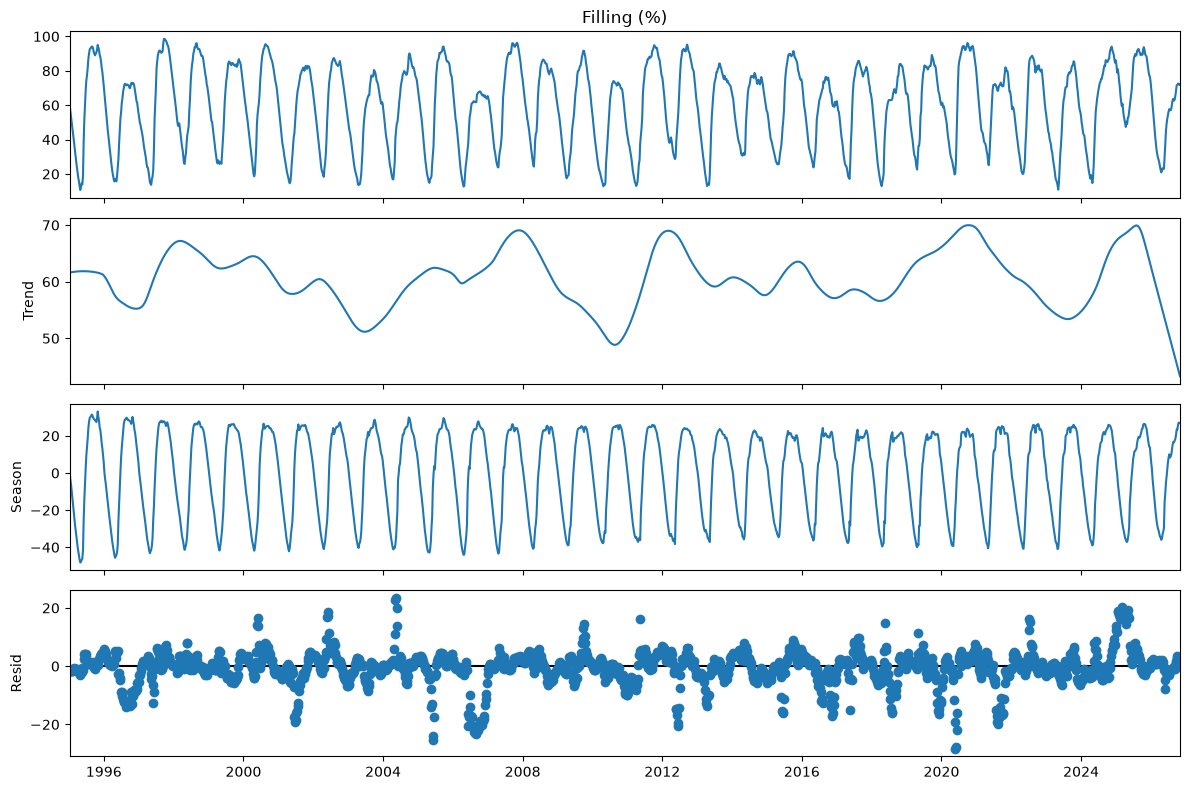

In [ ]:
def reservoir_stl(filling, seasonal=7, trend=101, robust=True):
    """Return STL plot for a weekly filling series expressed in percent.

    seasonal smooths across annual cycles; trend is measured in weeks.
    Both smoother lengths must be odd; trend must exceed the 52-week period.
    """
    # Keeping all weeks, including week 53; 52 weeks approximates an annual cycle.
    filling = filling.sort_index().asfreq("7D")
    if len(filling) < 104 or not np.isfinite(filling.to_numpy()).all():
        raise ValueError("STL needs at least two years of complete weekly observations.")

    # Following the course's fit-and-plot workflow with adjustable smoothers.
    result = STL(filling, period=52, seasonal=seasonal, trend=trend, robust=robust).fit()
    fig = result.plot()
    fig.set_size_inches(12, 8)
    fig.tight_layout()
    return fig


# Selecting NO3's complete available history and converting the filling ratio to percent.
no3_filling = (reservoir_data.loc[
    (reservoir_data["area_type"] == "EL") & (reservoir_data["area_number"] == 3)
].set_index("date")["fill_level_ratio"].sort_index() * 100).rename("Filling (%)")

# Testing the function with the default smoothers and robust fitting.
stl_figure = reservoir_stl(no3_filling)
plt.show()


## 10. Reservoir Filling: Spectrogram

This spectrogram shows which frequencies that dominates the data. The yellow line at approximately 0,02 gives us an indication that there is a dominant pattern with the frequency of 0,02 cycles per week. This equals one cycle per year, which we can see with out eyes in the data as well. If the yellow line was to incline through the dataset, this would mean that the frequency was developing into a highter value with time. 

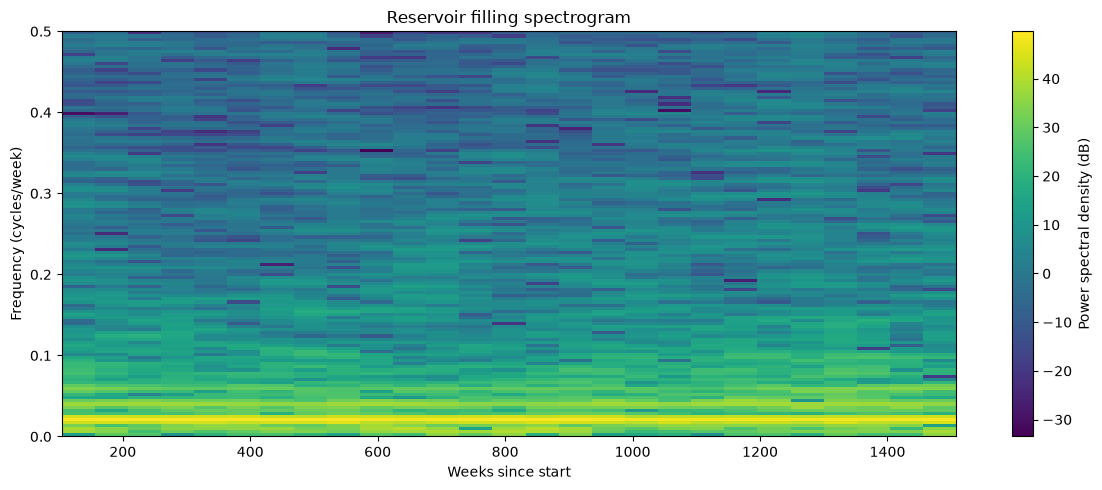

In [ ]:
def reservoir_spectrogram(filling, window_length=260, window_overlap=208):
    """Return a spectrogram of weekly filling percentages; window sizes are weeks."""
    # Keeping the same regular weekly timeline as STL, including ISO week 53.
    filling = filling.sort_index().asfreq("7D")
    if not np.isfinite(filling.to_numpy()).all():
        raise ValueError("The filling series must contain complete, finite weekly observations.")
    if not 2 <= window_length <= len(filling) or not 0 <= window_overlap < window_length:
        raise ValueError("Use 2 <= window_length <= series length and 0 <= overlap < window_length.")

    # Following the course's specgram example; centring each window removes its mean level.
    fig, ax = plt.subplots(figsize=(12, 5))
    _, _, _, image = ax.specgram(
        filling.to_numpy(), Fs=1, NFFT=window_length, noverlap=window_overlap,
        detrend="mean", scale="dB"
    )
    ax.set(title="Reservoir filling spectrogram", xlabel="Weeks since start",
           ylabel="Frequency (cycles/week)")
    fig.colorbar(image, ax=ax, label="Power spectral density (dB)")
    fig.tight_layout()
    return fig


# Testing the same NO3 history as STL with five-year windows and four-year overlap.
spectrogram_figure = reservoir_spectrogram(no3_filling)
plt.show()


## 11. Streamlit

### Preparing weather data for the app

The following screenshot shows the API-call calculator provided at [open-meteo](https://open-meteo.com/en/pricing):

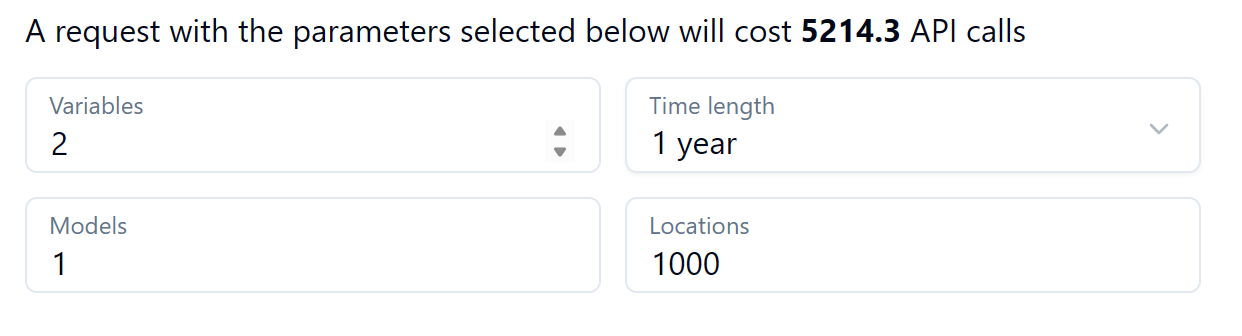

As the request for 1000 points over one year will require 5214 API calls and the houry limit from the source is 5000 calls, I want the app to run on fewer points by default. This will provide a better user experience, although it differs from the CA task of using 1000 coordinate pairs.

In order to provide an even more seamles user experience, we download the weather information for the given areas in 2024 and 2025 and store it in the mongoDB.  Hourly spatial means are computed in pandas and saved to `ind320_ca3.weather_hourly`. 


In [ ]:
def save_app_weather(years=(2024, 2025), pause_seconds=420.0):
    """Save hourly regional ERA5 means for 100 reproducible points per region.

    Complete region-years in MongoDB and validated local responses are reused.
    HTTP 429 stops the run without retries; running this cell again resumes it.
    """
    if not years or any(not isinstance(year, int) or not 1940 <= year <= 2025 for year in years):
        raise ValueError("Choose historical years from 1940 through 2025.")
    if not np.isfinite(pause_seconds) or pause_seconds < 0:
        raise ValueError("pause_seconds must be finite and non-negative.")
    variables = ["temperature_2m", "precipitation"]
    units = {"temperature_2m": "°C", "precipitation": "mm"}
    url = "https://archive-api.open-meteo.com/v1/archive"
    coursework_folder = shapefile_folder.resolve().parent

    # Reading the existing private MongoDB setting without displaying credentials.
    with (coursework_folder.parent / ".streamlit/secrets.toml").open("rb") as secrets_file:
        mongo_uri = tomllib.load(secrets_file)["mongo"]["uri"]
    last_request_time = None
    summary = []
    try:
        with MongoClient(mongo_uri, serverSelectionTimeoutMS=10000, tz_aware=True) as client:
            client.admin.command("ping")
            collection = client["ind320_ca3"]["weather_hourly"]
            # Indexing region, sample and time for coverage checks and later app queries.
            collection.create_index([("region", 1), ("sample_id", 1), ("time", 1)], unique=True)
            with requests.Session() as session:
                for region_id, coordinates in sorted(region_locations.items()):
                    # Selecting a random subset rather than the first spatially ordered points.
                    locations = np.asarray(coordinates, dtype=float)
                    if locations.shape != (1000, 2) or not np.isfinite(locations).all():
                        raise ValueError(f"{region_id} must have 1000 finite coordinate pairs.")
                    if (np.abs(locations) > [180, 90]).any():
                        raise ValueError(f"Invalid coordinates for {region_id}.")
                    indices = np.sort(np.random.default_rng(42).choice(1000, 100, replace=False))
                    selected = locations[indices]
                    params = {
                        "latitude": ",".join(map(str, selected[:, 1])),
                        "longitude": ",".join(map(str, selected[:, 0])),
                        "hourly": ",".join(variables), "models": "era5", "timezone": "GMT",
                        "temperature_unit": "celsius", "precipitation_unit": "mm",
                    }
                    # Identifying the exact sample and model independently of the requested year.
                    sample_id = hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()
                    for year in sorted(set(years)):
                        params.update(start_date=f"{year}-01-01", end_date=f"{year}-12-31")
                        hours = pd.date_range(f"{year}-01-01", f"{year + 1}-01-01",
                                              freq="h", inclusive="left", tz="UTC")
                        query = {"region": region_id, "sample_id": sample_id,
                                 "time": {"$gte": hours[0].to_pydatetime(),
                                          "$lt": (hours[-1] + pd.Timedelta(hours=1)).to_pydatetime()}}
                        if collection.count_documents(query) == len(hours):
                            print(f"{region_id}/{year}: already saved ({len(hours)} hours).", flush=True)
                            summary.append({"region": region_id, "year": year, "hours": len(hours)})
                            continue

                        # Matching local checkpoints by all request parameters, including year.
                        request_key = hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()
                        folder = coursework_folder / "data/weather" / region_id / "app_100"
                        folder.mkdir(parents=True, exist_ok=True)
                        cache_path = folder / f"{request_key}.json"
                        cached = cache_path.is_file()
                        if cached:
                            payload = json.loads(cache_path.read_text(encoding="utf-8"))
                        else:
                            if last_request_time is not None:
                                wait = max(0, pause_seconds - (time.monotonic() - last_request_time))
                                print(f"{region_id}/{year}: waiting {wait:.0f} seconds before request.", flush=True)
                                time.sleep(wait)
                            print(f"{region_id}/{year}: requesting 100 points from Open-Meteo.", flush=True)
                            last_request_time = time.monotonic()
                            response = session.get(url, params=params, timeout=180)
                            if response.status_code == 429:
                                raise RuntimeError(
                                    f"Open-Meteo quota reached: {response.text}. "
                                    f"Retry-After: {response.headers.get('Retry-After', 'not supplied')}. "
                                    "Previous results are preserved; rerun later to resume."
                                )
                            response.raise_for_status()
                            payload = response.json()

                        # Checking all 100 series before averaging; identical model series stay included.
                        if not isinstance(payload, list) or len(payload) != 100:
                            raise ValueError("Expected exactly 100 weather responses.")
                        frames = []
                        for point in payload:
                            frame = pd.DataFrame(point["hourly"])[["time", *variables]]
                            frame["time"] = pd.to_datetime(frame["time"], utc=True)
                            if not pd.DatetimeIndex(frame["time"]).equals(hours):
                                raise ValueError("Unexpected hourly coverage.")
                            if any(point["hourly_units"].get(v) != units[v] for v in variables):
                                raise ValueError("Unexpected weather units.")
                            frame[variables] = frame[variables].apply(pd.to_numeric, errors="raise")
                            if not np.isfinite(frame[variables].to_numpy(dtype=float)).all():
                                raise ValueError("Missing or non-finite weather values.")
                            frames.append(frame)
                        means = pd.concat(frames, ignore_index=True).groupby("time")[variables].mean()
                        if not cached:
                            temporary_path = cache_path.with_suffix(".tmp")
                            temporary_path.write_text(json.dumps(payload, allow_nan=False), encoding="utf-8")
                            temporary_path.replace(cache_path)

                        # Upserting hourly means so interruptions and reruns cannot create duplicates.
                        writes = []
                        for hour, row in means.iterrows():
                            document = {
                                "region": region_id, "time": hour.to_pydatetime(),
                                "temperature_2m": float(row["temperature_2m"]),
                                "precipitation": float(row["precipitation"]),
                                "sample_id": sample_id, "sample_size": 100, "sample_seed": 42,
                                "model": "era5", "timezone": "UTC", "units": units, "source": url,
                            }
                            key = f"{region_id}:{sample_id}:{hour.isoformat()}"
                            writes.append(UpdateOne({"_id": key}, {"$set": document}, upsert=True))
                        collection.bulk_write(writes, ordered=False)
                        if collection.count_documents(query) != len(hours):
                            raise RuntimeError("MongoDB hourly coverage is incomplete; rerun to resume.")
                        print(f"{region_id}/{year}: saved {len(hours)} hourly means to MongoDB.", flush=True)
                        summary.append({"region": region_id, "year": year, "hours": len(hours)})
    except PyMongoError:
        raise RuntimeError("MongoDB operation failed; check connection, access and storage. Rerun to resume.") from None
    return pd.DataFrame(summary)


# Preparing app data for both years; running this cell downloads data and writes to MongoDB.
app_weather_summary = save_app_weather()
app_weather_summary


NO1/2024: requesting 100 points from Open-Meteo.
NO1/2024: saved 8784 hourly means to MongoDB.
NO1/2025: waiting 400 seconds before request.
NO1/2025: requesting 100 points from Open-Meteo.
NO1/2025: saved 8760 hourly means to MongoDB.
NO2/2024: waiting 400 seconds before request.
NO2/2024: requesting 100 points from Open-Meteo.
NO2/2024: saved 8784 hourly means to MongoDB.
NO2/2025: waiting 394 seconds before request.
NO2/2025: requesting 100 points from Open-Meteo.
NO2/2025: saved 8760 hourly means to MongoDB.
NO3/2024: waiting 406 seconds before request.
NO3/2024: requesting 100 points from Open-Meteo.
NO3/2024: saved 8784 hourly means to MongoDB.
NO3/2025: waiting 398 seconds before request.
NO3/2025: requesting 100 points from Open-Meteo.
NO3/2025: saved 8760 hourly means to MongoDB.
NO4/2024: waiting 398 seconds before request.
NO4/2024: requesting 100 points from Open-Meteo.
NO4/2024: saved 8784 hourly means to MongoDB.
NO4/2025: waiting 394 seconds before request.
NO4/2025: req

,region,year,hours
0,NO1,2024,8784
1,NO1,2025,8760
2,NO2,2024,8784
3,NO2,2025,8760
4,NO3,2024,8784
5,NO3,2025,8760
6,NO4,2024,8784
7,NO4,2025,8760
8,NO5,2024,8784
9,NO5,2025,8760
